## TAsk-1 [19Nov]
## Analyze the distribution of ratings and recommendations by identifying patterns using advanced statistical techniques such as Gaussian mixture modeling, detecting anomalies, and segmenting data for deeper trend insights.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

sns.set_theme(style="whitegrid")

df = pd.read_csv("../17nov/cleaned_day1.csv")
df.head()

,brand_name,division_name,department_name,class_name,launch_year,season,occasion,fabric_type,pattern,color,...,fit_feedback,customer_rating,review_word_count,sentiment_score,positive_feedback_count,social_media_trend_score,return_rate_pct,monthly_units_sold,recommended_ind,trend_demand_status
0,W for Woman,Ethnic & Fusion,Fusion Wear,Palazzos & Tunics,2024,Summer,Festive,Cotton Blend,Floral,Sky Blue,...,Runs Small,4,12,0.402,0.693147,58.5,24.3,401.0,1,Slow Moving / Low Demand
1,Forever 21,General Petite,Dresses,Party Dresses,2025,Winter,Casual,Satin,Floral,Sky Blue,...,True to Size,4,34,0.558,2.708050,86.5,15.0,466.0,1,Trending / High Demand
2,AND,General,Bottoms,Shorts,2022,Summer,NaN,Polyester,Checked,Mustard,...,True to Size,5,28,0.785,1.386294,48.0,22.7,466.0,1,Steady / Moderate Demand
3,Marks & Spencer,Intimates,Intimate,Lounge,2024,Winter,Daily Wear,Cotton,Polka Dot,Olive Green,...,True to Size,5,44,0.889,2.302585,62.5,18.2,461.0,1,Steady / Moderate Demand
4,H&M,General,Jackets,Denim Jackets,2022,Autumn,Streetwear,Denim,Solid,Olive Green,...,True to Size,5,41,0.572,1.098612,76.1,10.7,516.0,1,Trending / High Demand


In [14]:
num_cols = [
    "customer_age", "mrp", "discount_pct", "selling_price",
    "material_quality_score", "review_word_count", "sentiment_score",
    "positive_feedback_count", "social_media_trend_score",
    "return_rate_pct", "monthly_units_sold"
]
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

cat_cols = df.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Loaded and Prepared Dataset Shape:", df.shape)

Loaded and Prepared Dataset Shape: (5461, 28)


In [15]:
gmm_features = [
    "customer_rating", "recommended_ind", "sentiment_score",
    "material_quality_score", "return_rate_pct"
]

scaler = StandardScaler()
X_gmm = scaler.fit_transform(df[gmm_features])

gmm = GaussianMixture(n_components=3, random_state=42)
df["gmm_segment"] = gmm.fit_predict(X_gmm)

log_probs = gmm.score_samples(X_gmm)
anomaly_threshold = np.percentile(log_probs, 2)
df["gmm_anomaly"] = (log_probs < anomaly_threshold).astype(int)

print("Anomalies Detected:", df["gmm_anomaly"].sum())
print("\nSegment Profile Summary:")
print(df.groupby("gmm_segment")[gmm_features].mean().round(2))

Anomalies Detected: 110

Segment Profile Summary:
             customer_rating  recommended_ind  sentiment_score  \
gmm_segment                                                      
0                       4.26              1.0             0.53   
1                       2.00              0.0            -0.41   
2                       3.45              0.0             0.22   

             material_quality_score  return_rate_pct  
gmm_segment                                           
0                              3.94            15.35  
1                              2.99            37.64  
2                              3.62            23.59  


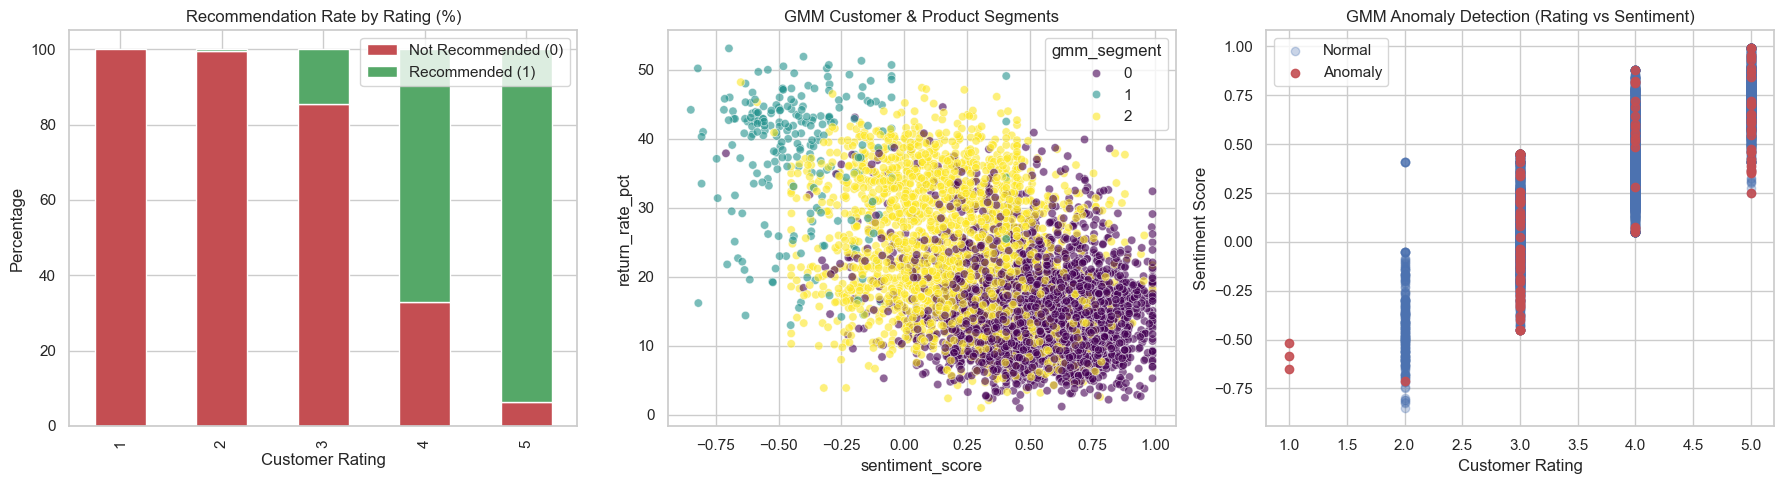

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

rating_rec = pd.crosstab(df["customer_rating"], df["recommended_ind"], normalize="index") * 100
rating_rec.plot(kind="bar", stacked=True, ax=axes[0], color=["#C44E52", "#55A868"])
axes[0].set_title("Recommendation Rate by Rating (%)")
axes[0].set_xlabel("Customer Rating")
axes[0].set_ylabel("Percentage")
axes[0].legend(["Not Recommended (0)", "Recommended (1)"])

sns.scatterplot(
    data=df, x="sentiment_score", y="return_rate_pct",
    hue="gmm_segment", palette="viridis", alpha=0.6, ax=axes[1]
)
axes[1].set_title("GMM Customer & Product Segments")

normal_df = df[df["gmm_anomaly"] == 0]
anom_df = df[df["gmm_anomaly"] == 1]
axes[2].scatter(normal_df["customer_rating"], normal_df["sentiment_score"], alpha=0.3, label="Normal", color="#4C72B0")
axes[2].scatter(anom_df["customer_rating"], anom_df["sentiment_score"], alpha=0.9, label="Anomaly", color="#C44E52")
axes[2].set_title("GMM Anomaly Detection (Rating vs Sentiment)")
axes[2].set_xlabel("Customer Rating")
axes[2].set_ylabel("Sentiment Score")
axes[2].legend()

plt.tight_layout()
plt.show()

## Task-2 
## Compute correlation between numerical variables by implementing multiple correlation metrics (Pearson, Spearman, Kendall), dynamically filtering significant correlations, and enhancing heatmap visualizations with hierarchical clustering to identify related feature groups.

In [17]:
corr_cols = num_cols + ["customer_rating", "recommended_ind"]

pearson_corr = df[corr_cols].corr(method="pearson")
spearman_corr = df[corr_cols].corr(method="spearman")
kendall_corr = df[corr_cols].corr(method="kendall")

significant_pairs = []
for i in range(len(corr_cols)):
    for j in range(i + 1, len(corr_cols)):
        f1, f2 = corr_cols[i], corr_cols[j]
        p_val = pearson_corr.loc[f1, f2]
        s_val = spearman_corr.loc[f1, f2]
        k_val = kendall_corr.loc[f1, f2]
        if abs(p_val) >= 0.35 or abs(s_val) >= 0.35:
            significant_pairs.append({
                "Feature_1": f1,
                "Feature_2": f2,
                "Pearson": round(p_val, 3),
                "Spearman": round(s_val, 3),
                "Kendall": round(k_val, 3)
            })

sig_corr_df = pd.DataFrame(significant_pairs).sort_values(by="Pearson", key=abs, ascending=False).reset_index(drop=True)
print("Dynamically Filtered Significant Correlations (|r| >= 0.35):")
print(sig_corr_df)

Dynamically Filtered Significant Correlations (|r| >= 0.35):
                   Feature_1           Feature_2  Pearson  Spearman  Kendall
0                        mrp       selling_price    0.877     0.898    0.729
1            sentiment_score     customer_rating    0.824     0.810    0.681
2         monthly_units_sold     customer_rating    0.600     0.598    0.478
3            customer_rating     recommended_ind    0.599     0.609    0.571
4     material_quality_score     customer_rating    0.574     0.563    0.459
5            return_rate_pct     customer_rating   -0.568    -0.515   -0.404
6            sentiment_score     recommended_ind    0.548     0.555    0.454
7            sentiment_score     return_rate_pct   -0.502    -0.431   -0.293
8            sentiment_score  monthly_units_sold    0.501     0.482    0.332
9            return_rate_pct     recommended_ind   -0.493    -0.477   -0.390
10    material_quality_score     sentiment_score    0.471     0.457    0.321
11           re

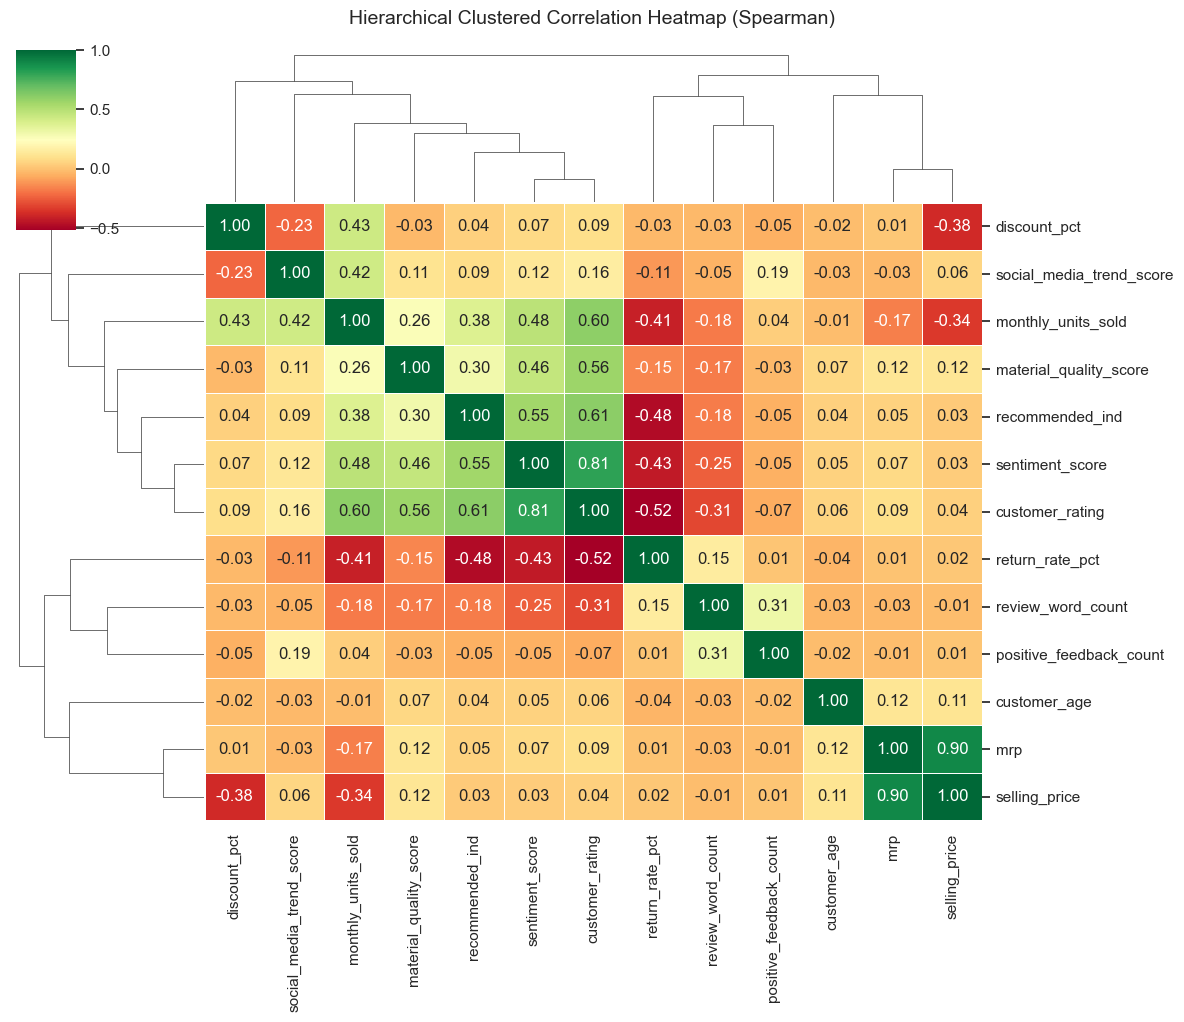

In [18]:
cluster_grid = sns.clustermap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    figsize=(12, 10),
    linewidths=0.5
)
cluster_grid.fig.suptitle("Hierarchical Clustered Correlation Heatmap (Spearman)", y=1.02, fontsize=14)
plt.show()

## Task-3
## Generate summary statistics and insights by developing a custom report generator that not only calculates key statistics (mean, median, variance) but also interprets trends using natural language processing, providing automated, human-readable data summaries.

In [19]:
def generate_automated_nlp_report(data, numerical_columns):
    stats_summary = pd.DataFrame({
        "Mean": data[numerical_columns].mean().round(2),
        "Median": data[numerical_columns].median().round(2),
        "Variance": data[numerical_columns].var().round(2),
        "Std_Dev": data[numerical_columns].std().round(2),
        "Skewness": data[numerical_columns].skew().round(2)
    })
    print("STATISTICAL METRICS TABLE:")
    print(stats_summary)
    print("\n" + "=" * 65)
    print("AUTOMATED NATURAL LANGUAGE DATA SUMMARY REPORT")
    print("=" * 65)

    top_dept = data["department_name"].value_counts().idxmax()
    top_dept_pct = round(data["department_name"].value_counts(normalize=True).max() * 100, 1)
    top_brand = data.groupby("brand_name")["monthly_units_sold"].mean().idxmax()
    rec_rate = round(data["recommended_ind"].mean() * 100, 1)
    avg_rating = round(data["customer_rating"].mean(), 2)
    avg_price = round(data["selling_price"].mean(), 2)
    med_price = round(data["selling_price"].median(), 2)
    price_skew = round(data["selling_price"].skew(), 2)
    top_season = data.groupby("season")["monthly_units_sold"].mean().idxmax()

    sentences = [
        f"1. Overall Market Volume: The dataset covers {len(data)} women's clothing items, led by the {top_dept} department ({top_dept_pct}% share).",
        f"2. Customer Satisfaction: The average product rating is {avg_rating}/5.0, with an overall recommendation rate of {rec_rate}%.",
        f"3. Pricing Distribution: The mean selling price is {avg_price} against a median of {med_price} (skewness: {price_skew}), indicating a right-skewed premium price tail.",
        f"4. Brand & Seasonal Demand: {top_brand} achieves the highest average monthly unit sales, while {top_season} is the peak performing season.",
        f"5. Quality & Returns Insight: Segment 0 represents high-rated, low-return products, whereas {data['gmm_anomaly'].sum()} anomalous items show mismatched rating-to-sentiment behavior."
    ]

    for line in sentences:
        print(line)

generate_automated_nlp_report(df, num_cols)

STATISTICAL METRICS TABLE:
                             Mean   Median    Variance  Std_Dev  Skewness
customer_age                28.61    28.00       54.76     7.40      0.66
mrp                       2572.80  2229.00  1981950.65  1407.82      0.92
discount_pct                30.82    30.00      289.49    17.01      0.35
selling_price             1807.35  1499.60  1407550.46  1186.40      1.72
material_quality_score       3.77     3.80        0.38     0.61     -0.11
review_word_count           57.96    57.00      687.70    26.22      0.29
sentiment_score              0.36     0.41        0.11     0.33     -0.64
positive_feedback_count      1.81     1.79        0.24     0.49      0.06
social_media_trend_score    70.66    70.90      220.96    14.86     -0.11
return_rate_pct             19.65    17.40       92.49     9.62      0.79
monthly_units_sold         428.60   432.00     6185.38    78.65     -0.11

AUTOMATED NATURAL LANGUAGE DATA SUMMARY REPORT
1. Overall Market Volume: The dataset

In [20]:
df.to_csv("cleaned_day3.csv", index=False)
print("Saved dataset to cleaned_day3.csv")

Saved dataset to cleaned_day3.csv
